# Grafted neuron morphology, 2WPT — Airyscan-processed images

**Question:** do grafted **bmi1** neurons differ in morphology from **scr** neurons? The researcher asked
for any shape difference, in particular the diameter of the extensions.

**Data (`2WPT/`):**
- Two mice. **ID06902** has both scr and bmi1. **ID06914** has scr only and is used as a second-mouse
  reference.
- This notebook uses **only the Airyscan-processed files (`*Airyscan Processing*.czi`), which are single planes**.
  The regular CZI files are analysed separately in
  `morphology_2WPT_czi.ipynb`.
- **Neurons:** the `AF594-T1` channel. `DAPI` is the nuclear stain. `AF405`, where present, is a
  diffuse tissue signal, not nuclei. Channels are picked **by name**, because their order changes
  between files.
- **Pixel sizes:** 35.3, 54.8 and 70.6 nm, from 63x and 40x objectives. Every image is resampled to
  70.6 nm, so all measurements are in µm.

**Pipeline** (`morphology_utils.py`, shared by both notebooks):
1. **Background:** subtract a large Gaussian (σ = 5 µm) and divide by robust noise, giving an SNR image.
2. **AF594 mask:** the FAST U-Net++ filament mask (pretrained, also used for the axon breaks) united
   with SNR > 3. A piece is kept only if it contains clearly bright signal (SNR > 6).
3. **Cell bodies:** Cellpose-SAM at 0.12 µm/px. Keep objects of 30–900 µm² with solidity ≥ 0.85 and
   positive AF594 signal.
4. **Extensions:** the mask minus cell bodies, skeletonized; end branches < 2 µm are pruned. Each
   branch gets its length and tortuosity (path length / straight distance).
5. **Extension diameter:** the **FWHM of the intensity profile across the branch**, measured every
   0.5 µm. This is threshold-free, so a brightness difference between conditions does not change the
   width. Per branch: the median width and its CV along the branch (high CV = beaded / varicose).
6. **Per cell body:** area, max length, circularity, aspect ratio, number of primary extensions
   (AF594 pieces crossing a 1–3 µm ring), and primary-extension diameter (widths 1–5 µm from the soma).
7. **Dense clusters vs isolated neurons:** many bmi1 fields show a dense graft core, a mesh of packed
   cells and overlapping processes. There, skeleton crossings count as branch points and packed
   membranes measure as thick extensions. Each point gets the local AF594 mask fraction in a 20 µm
   window; above 0.20 counts as a dense cluster. The **isolated-extension metrics** use only points
   below that, which is the fair comparison of single extensions. The share of extensions in dense
   clusters is reported as its own measure.
8. **Swellings**, matching Flamier et al. 2018, Fig 3F (% of axons with ≥ 1 swelling). A swelling is a
   run of width samples that meets all of these:
   - wider than 2× the branch's median width, and at least 0.3 µm wider;
   - brighter than 1.2× the branch's median peak intensity;
   - wider than the samples just outside it;
   - at least 2 µm from either branch end, so junction blobs are not counted.

   Reported as % of branches (≥ 3 µm) with at least one swelling, and as swellings per 100 µm.
9. **Isolated neurons** (Flamier et al. 2018, Fig 2B): a cell body counts as isolated when the
   AF594 mask covers < 8.5% of a 1–20 µm ring around it and no other cell body lies within 10 µm.
   The threshold was calibrated by eye: clearly isolated neurons 5–8%, cells in graft cores mostly
   9–29%. The margin is thin, so check the gallery of all isolated neurons. Each AF594 mask pixel goes to the
   nearest cell body along the mask, with gaps ≤ 1 µm bridged. Per neuron:
   - **dendrite length**;
   - **dendrite surface area**, π × mean FWHM diameter × length, which is what IMARIS reports as
     "dendrite area" (the paper's ~6,500 µm² for ~2,300 µm of dendrite implies ~0.9 µm diameter);
   - **dendritic field area**, the convex hull of the arbor;
   - **branch points and tips**.

**Statistics:** one value per image, or per cell body for soma metrics. The main test is a
Mann-Whitney test of **bmi1 vs scr within mouse ID06902**, the only mouse with both conditions. The
scr ID06902 vs scr ID06914 test shows how much two mice differ in the same condition.

In [1]:
import os, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, '/Users/ctuna/Desktop/axon_codes/results_2WPT')
import importlib, morphology_utils as mu
importlib.reload(mu)

AIRYSCAN = True
DATA_DIR = '/Users/ctuna/Desktop/axon_codes/2WPT'
OUT_DIR  = '/Users/ctuna/Desktop/axon_codes/results_2WPT/airyscan'
CSV_DIR, FIG_DIR = os.path.join(OUT_DIR, 'csv'), os.path.join(OUT_DIR, 'figures')
os.makedirs(CSV_DIR, exist_ok=True); os.makedirs(FIG_DIR, exist_ok=True)
pd.set_option('display.width', 200)

## Files and channels

In [2]:
files = mu.list_images(DATA_DIR, airyscan=AIRYSCAN)
print(len(files), 'images')
display(files.groupby(['mouse', 'condition']).agg(n=('filename', 'size'),
        pixel_nm=('px_nm', lambda s: sorted(set(s))), objective=('objective', lambda s: sorted(set(s))),
        z_planes=('n_z', lambda s: f'{s.min()}–{s.max()}')))
display(files.groupby(['mouse', 'condition'])['channels'].value_counts().rename('n').to_frame())

58 images


n      pixel_nm     objective z_planes
mouse   condition                                         
ID06902 bmi1       26        [35.3]  [C 63x/1.40]      1–1
        scr        19        [35.3]  [C 63x/1.40]      1–1
ID06914 scr        13  [35.3, 54.8]  [C 63x/1.40]      1–1

n
mouse   condition channels                     
ID06902 bmi1      AF594-T1,DAPI-T3           12
                  AF594-T1,AF405-T2          12
                  AF594-T1,AF488-T2,DAPI-T3   2
        scr       AF594-T1,DAPI-T3           15
                  AF594-T1,AF405-T2           3
                  AF594-T1,AF488-T2,DAPI-T3   1
ID06914 scr       AF594-T1,DAPI-T2            9
                  AF594-T1,DAPI-T3            4

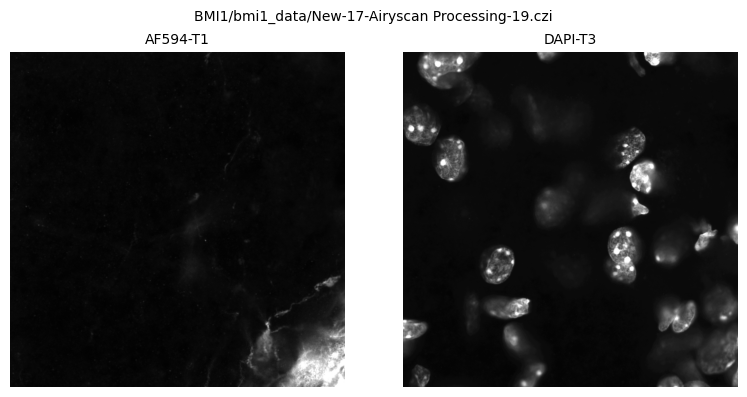

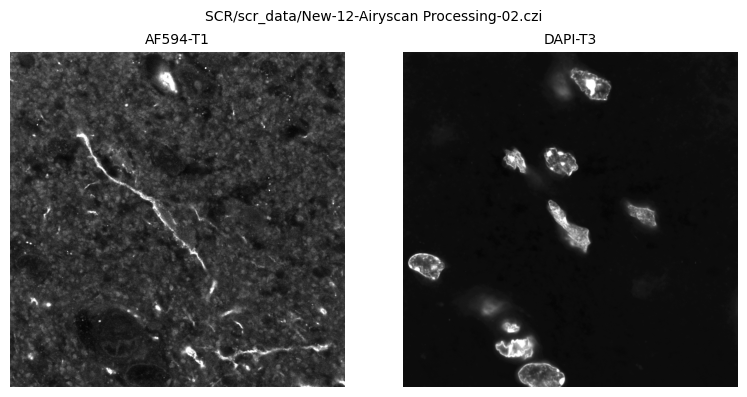

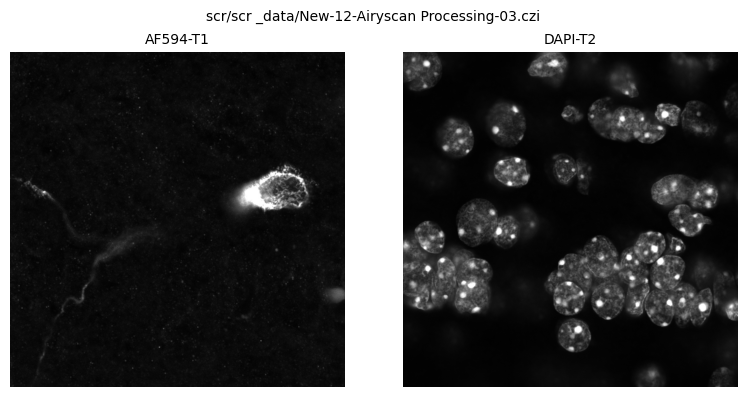

In [3]:
# one example per group, all channels
for (m, c), g in files.groupby(['mouse', 'condition']):
    mu.plot_channels(g.iloc[len(g) // 2]['path'],
                     save=os.path.join(FIG_DIR, f'channels_{m}_{c}.png'))

## Run the analysis on every image

In [4]:
images, branches, somata, _ = mu.analyze_all(files)
images.to_csv(os.path.join(CSV_DIR, 'morphology_images_airyscan.csv'), index=False)
branches.to_csv(os.path.join(CSV_DIR, 'morphology_branches_airyscan.csv'), index=False)
somata.to_csv(os.path.join(CSV_DIR, 'morphology_somata_airyscan.csv'), index=False)
print(f'{len(images)} images, {len(branches)} branches, {len(somata)} cell bodies')
display(mu.add_group(images).groupby('group')[['n_somata', 'ext_length_um', 'n_branches']].sum())

58 images, 3909 branches, 47 cell bodies


,n_somata,ext_length_um,n_branches
group,,,
ID06902 bmi1,20,6268.8564,846
ID06902 scr,6,4266.4286,577
ID06914 scr,21,3676.6362,443


## Segmentation examples

For each group: the image with the most cell bodies and the image with the most extension length.
Dots along the extensions show the measured diameter.

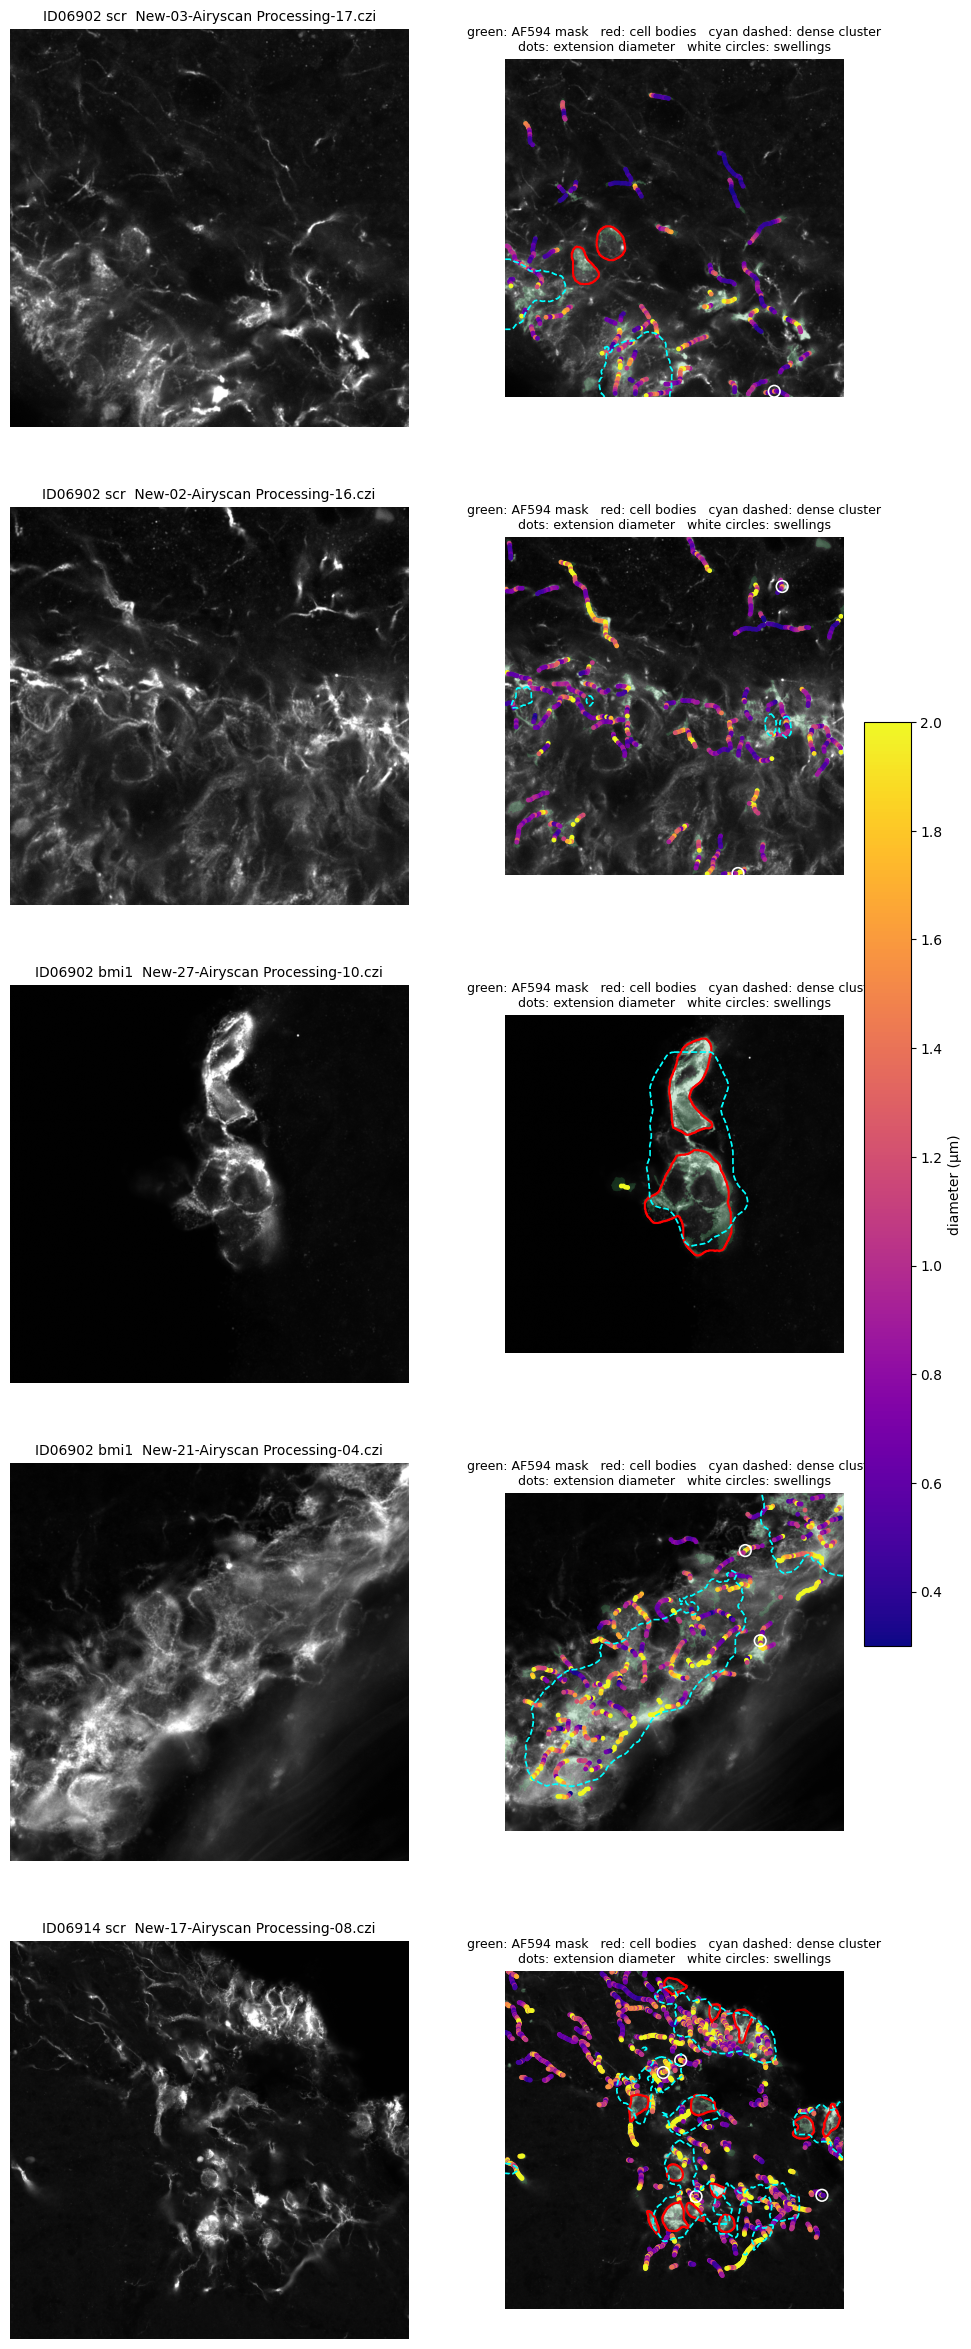

In [5]:
ex = []
for gname in mu.GROUP_ORDER:
    sub = mu.add_group(images).query('group == @gname')
    if not len(sub):
        continue
    picks = list(dict.fromkeys([sub.sort_values(['n_somata', 'ext_length_um']).iloc[-1]['filename'],
                                sub.sort_values('ext_length_um').iloc[-1]['filename']]))
    for fn in picks:
        p = files[(files['filename'] == fn) & (files['mouse'] + ' ' + files['condition'] == gname)]['path'].iloc[0]
        ex.append((f'{gname}  {fn}', mu.analyze_image(p)[3]))
mu.plot_examples(ex, save=os.path.join(FIG_DIR, 'segmentation_examples_airyscan.png'))

### Diameter check: FWHM widths drawn across the extensions around one cell body

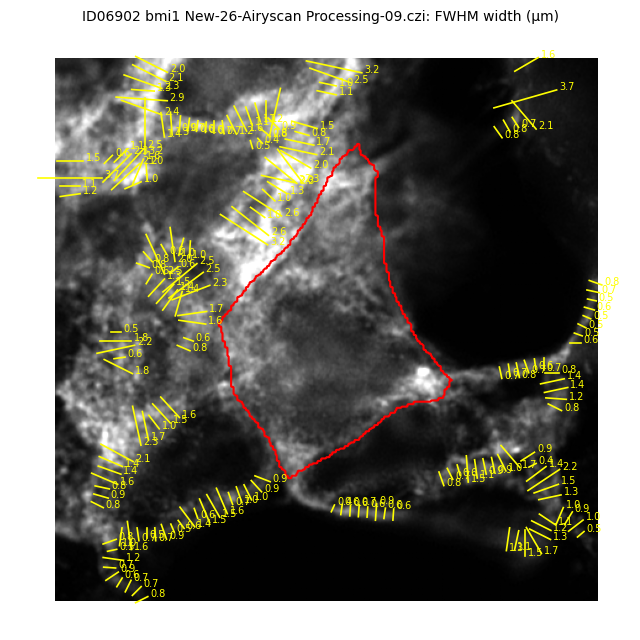

In [6]:
if len(somata):
    s = somata.sort_values(['n_primary_extensions', 'soma_area_um2']).iloc[-1]
    p = files[(files['filename'] == s['filename']) & (files['mouse'] == s['mouse'])
              & (files['condition'] == s['condition'])]['path'].iloc[0]
    a = mu.analyze_image(p)[3]
    from skimage.measure import regionprops
    cy, cx = [int(v) for v in regionprops((a['somata'] == s['soma_id']).astype(int))[0].centroid]
    mu.plot_diameter_zoom(a, (cy, cx), half=220, save=os.path.join(FIG_DIR, 'diameter_check_airyscan.png'),
                          title=f"{s['mouse']} {s['condition']} {s['filename']}: FWHM width (µm)")

## Extensions: one point per image

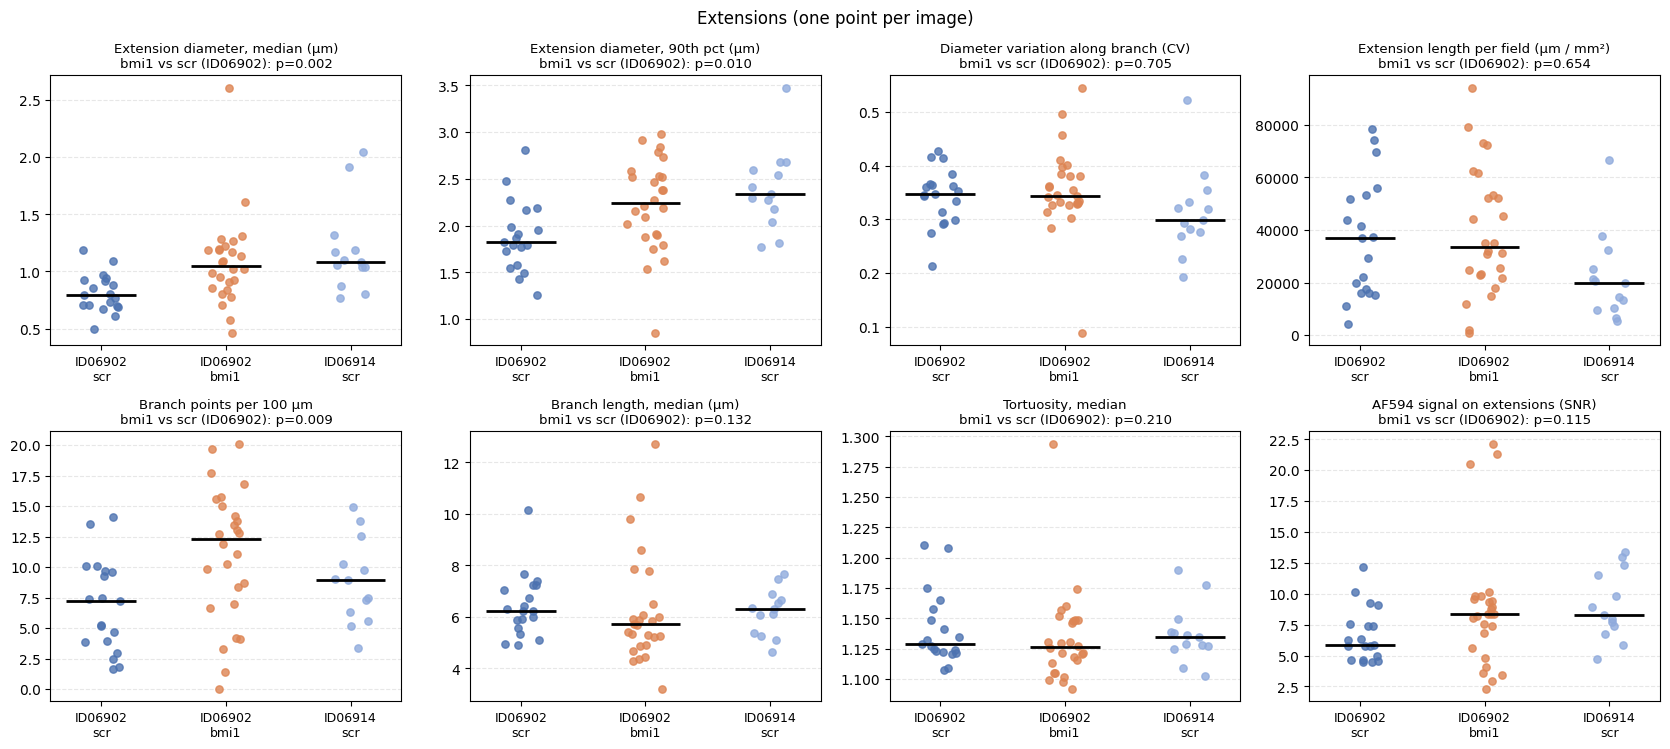

,ID06902 scr,ID06902 bmi1,ID06914 scr,n ID06902 scr,n ID06902 bmi1,n ID06914 scr,bmi1/scr (ID06902),"p bmi1 vs scr, ID06902",p bmi1 vs all scr,p scr ID06902 vs ID06914
metric,,,,,,,,,,
"Extension diameter, median (µm)",0.794,1.052,1.081,19,26,13,1.326,0.002,0.073,0.001
"Extension diameter, 90th pct (µm)",1.822,2.241,2.339,19,26,13,1.230,0.010,0.186,0.002
Diameter variation along branch (CV),0.347,0.344,0.299,19,26,13,0.992,0.705,0.116,0.078
Extension length per field (µm / mm²),36856.395,33499.543,19692.765,19,26,13,0.909,0.654,0.116,0.050
Branch points per 100 µm,7.246,12.317,8.958,19,26,13,1.700,0.009,0.011,0.156
"Branch length, median (µm)",6.226,5.707,6.291,19,26,13,0.917,0.132,0.109,0.848
"Tortuosity, median",1.129,1.126,1.135,19,26,13,0.997,0.210,0.171,0.788
AF594 signal on extensions (SNR),5.850,8.356,8.247,19,26,13,1.429,0.115,0.458,0.009


In [7]:
mu.plot_strips(images, mu.IMAGE_METRICS, save=os.path.join(FIG_DIR, 'extension_metrics_airyscan.png'),
               title='Extensions (one point per image)')
ext_stats = mu.stats_table(images, mu.IMAGE_METRICS)
ext_stats.to_csv(os.path.join(CSV_DIR, 'stats_extensions_airyscan.csv'))
ext_stats.round(3)

### Per-branch distributions (all branches ≥ 3 µm pooled per group; for the shape of the distribution, not for p-values)

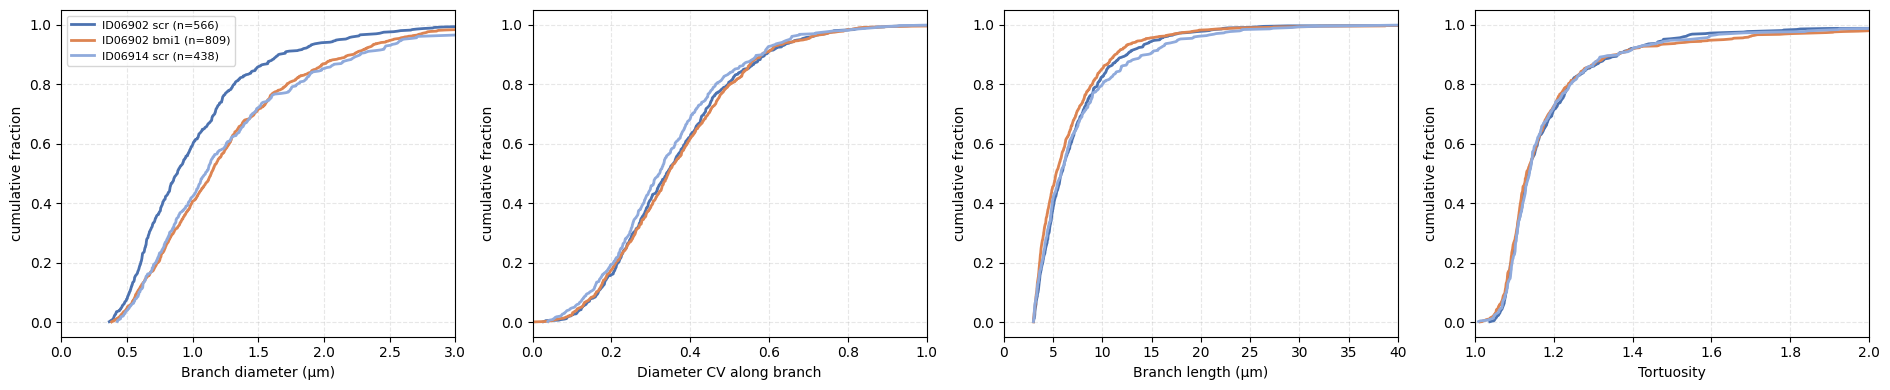

In [8]:
mu.plot_branch_distributions(branches, save=os.path.join(FIG_DIR, 'branch_distributions_airyscan.png'))

## Isolated extensions only (dense graft cores removed)

This is the main comparison of extension shape. The all-extension plots above mix single extensions
with the dense mesh of graft cores, which bmi1 fields contain more often.

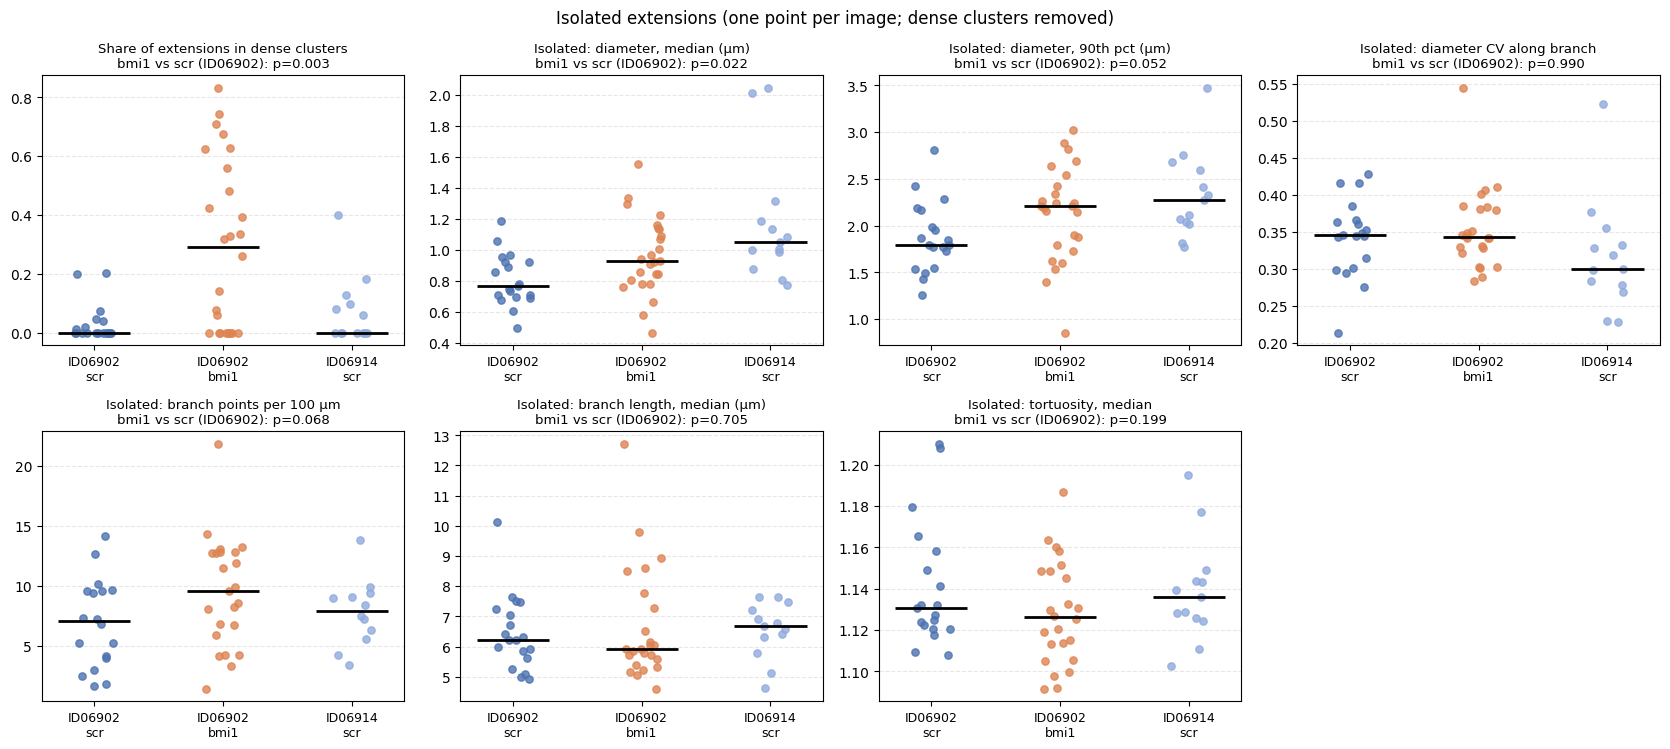

,ID06902 scr,ID06902 bmi1,ID06914 scr,n ID06902 scr,n ID06902 bmi1,n ID06914 scr,bmi1/scr (ID06902),"p bmi1 vs scr, ID06902",p bmi1 vs all scr,p scr ID06902 vs ID06914
metric,,,,,,,,,,
Share of extensions in dense clusters,0.000,0.291,0.000,19,26,13,inf,0.003,0.002,0.365
"Isolated: diameter, median (µm)",0.764,0.928,1.053,19,25,13,1.214,0.022,0.445,0.001
"Isolated: diameter, 90th pct (µm)",1.796,2.210,2.276,19,25,13,1.230,0.052,0.372,0.006
Isolated: diameter CV along branch,0.346,0.343,0.299,19,24,13,0.992,0.990,0.217,0.091
Isolated: branch points per 100 µm,7.037,9.558,7.910,18,23,12,1.358,0.068,0.080,0.539
"Isolated: branch length, median (µm)",6.226,5.911,6.668,19,24,13,0.949,0.705,0.471,0.420
"Isolated: tortuosity, median",1.131,1.126,1.136,19,24,13,0.996,0.199,0.157,0.759


In [9]:
mu.plot_strips(images, mu.ISO_METRICS, save=os.path.join(FIG_DIR, 'isolated_extension_metrics_airyscan.png'),
               title='Isolated extensions (one point per image; dense clusters removed)')
iso_stats = mu.stats_table(images, mu.ISO_METRICS)
iso_stats.to_csv(os.path.join(CSV_DIR, 'stats_isolated_extensions_airyscan.csv'))
iso_stats.round(3)

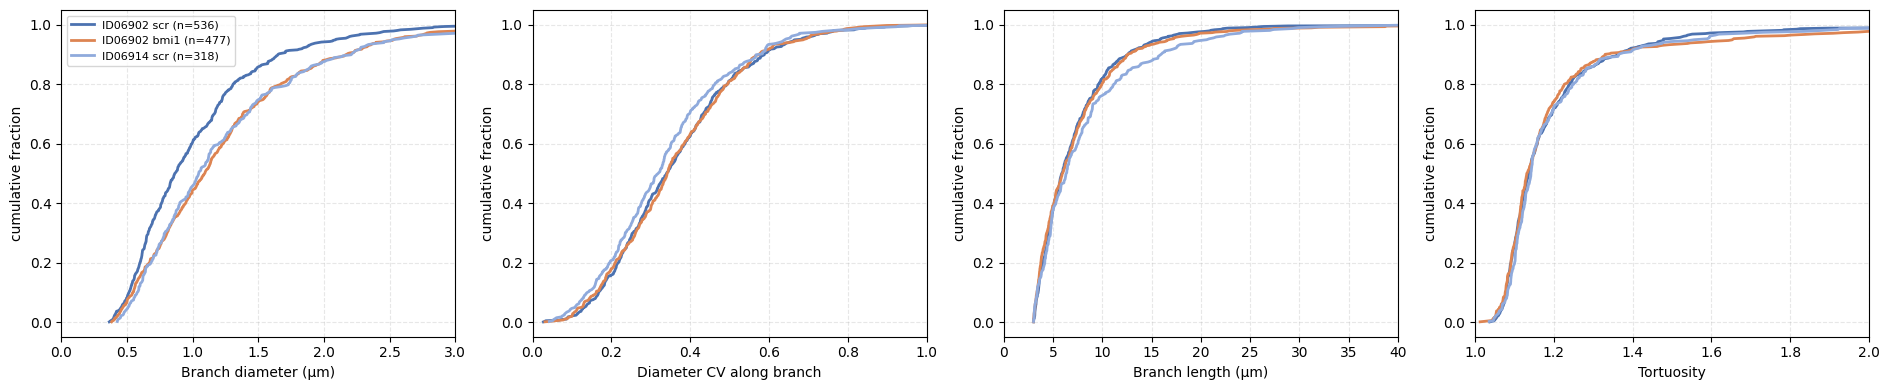

In [10]:
mu.plot_branch_distributions(branches, isolated_only=True,
                             save=os.path.join(FIG_DIR, 'branch_distributions_isolated_airyscan.png'))

## Swellings (Flamier et al. 2018, Fig 3F)

The paper counted the % of axons with at least one swelling (higher in shBMI1 neurons). Here the unit
is a skeleton branch, the closest equivalent; the per-length rate does not depend on that choice.
The isolated-only values are the main comparison.

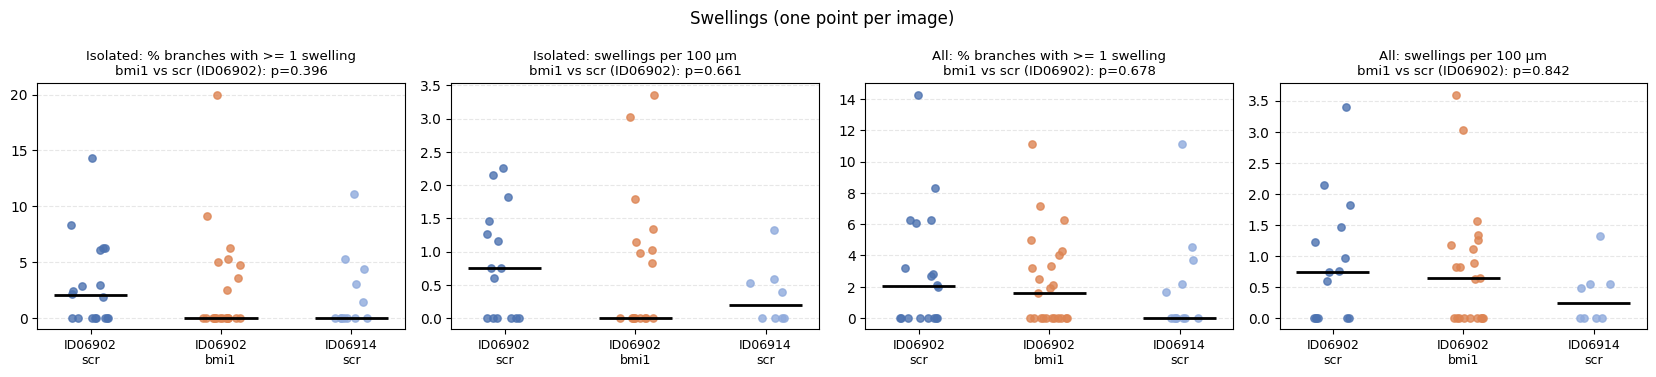

,ID06902 scr,ID06902 bmi1,ID06914 scr,n ID06902 scr,n ID06902 bmi1,n ID06914 scr,bmi1/scr (ID06902),"p bmi1 vs scr, ID06902",p bmi1 vs all scr,p scr ID06902 vs ID06914
metric,,,,,,,,,,
Isolated: % branches with >= 1 swelling,2.025,0.000,0.000,18,22,12,0.000,0.396,0.541,0.483
Isolated: swellings per 100 µm,0.747,0.000,0.197,15,17,8,0.000,0.661,0.977,0.213
All: % branches with >= 1 swelling,2.022,1.587,0.000,18,23,12,0.785,0.678,1.000,0.403
All: swellings per 100 µm,0.747,0.651,0.239,15,21,8,0.872,0.842,0.713,0.213


In [11]:
mu.plot_strips(images, mu.SWELL_METRICS, ncols=4, save=os.path.join(FIG_DIR, 'swelling_metrics_airyscan.png'),
               title='Swellings (one point per image)')
swell_stats = mu.stats_table(images, mu.SWELL_METRICS)
swell_stats.to_csv(os.path.join(CSV_DIR, 'stats_swellings_airyscan.csv'))
swell_stats.round(3)

### Swelling check: widths drawn across the extension, red = detected swelling (one example per group)

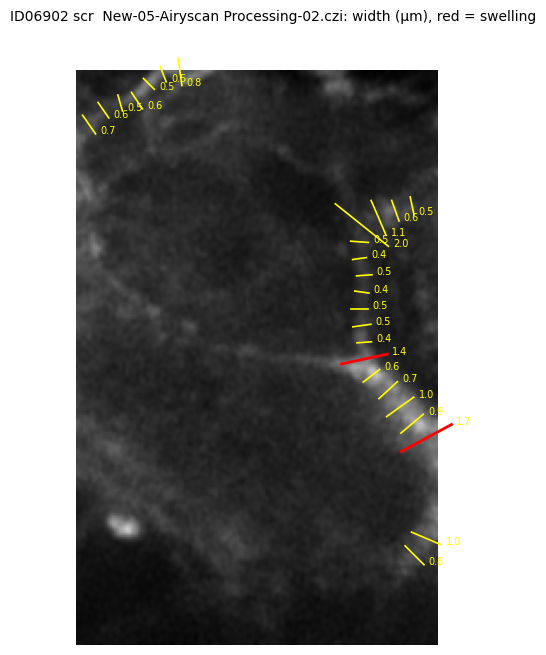

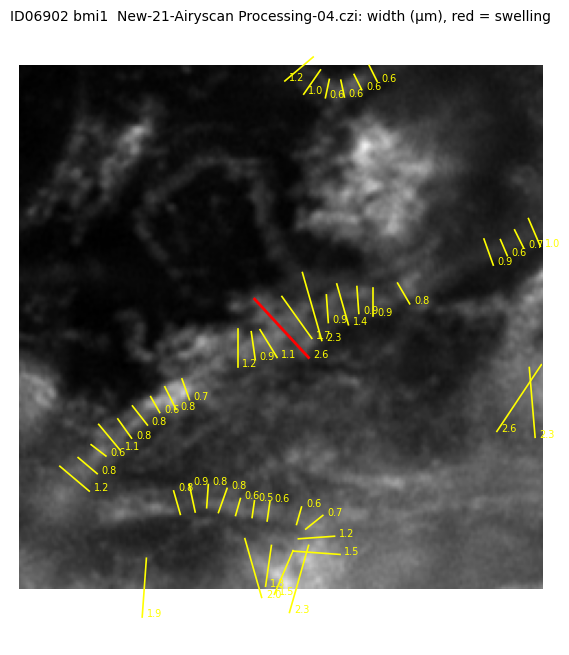

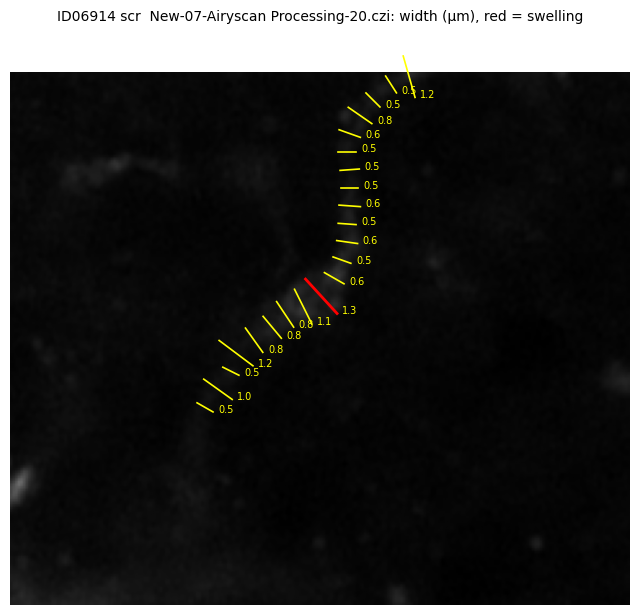

In [12]:
sw_br = mu.add_group(branches).query('n_swellings > 0 and local_density < @mu.DENSE_THR')
for gname in mu.GROUP_ORDER:
    g = sw_br[sw_br['group'] == gname]
    if not len(g):
        continue
    fn = mu.add_group(images).query('group == @gname').set_index('filename').loc[g['filename'].unique()] \
            ['iso_swellings_per_100um'].idxmax()
    p = files[(files['filename'] == fn) & (files['mouse'] + ' ' + files['condition'] == gname)]['path'].iloc[0]
    a = mu.analyze_image(p)[3]
    S = a['diam_samples']; sw = S[(S[:, 6] > 0) & (S[:, 5] < mu.DENSE_THR)]
    mu.plot_diameter_zoom(a, (int(sw[0, 0]), int(sw[0, 1])), half=120,
                          save=os.path.join(FIG_DIR, f'swelling_check_{gname.replace(" ", "_")}_airyscan.png'),
                          title=f'{gname}  {fn}: width (µm), red = swelling')

## Isolated neurons: dendrite length and area per neuron (Flamier et al. 2018, Fig 2B)

One point per isolated neuron, meaning a cell body outside dense clusters. Read these numbers with
the following in mind:
- **Lower bounds:** the images are 2D projections of thick tissue, and dendrites leave the focal
  volume and the field of view. Neurons whose dendrites reach the image edge are flagged (`touches_border`).
- **Crossings:** a fibre from another cell that crosses a dendrite can be assigned to the neuron.
- **Few neurons:** isolated bmi1 neurons are rare, as Iman noted.

,n_neurons,touching_edge
group,,
ID06902 scr,2,1
ID06902 bmi1,2,0
ID06914 scr,6,1


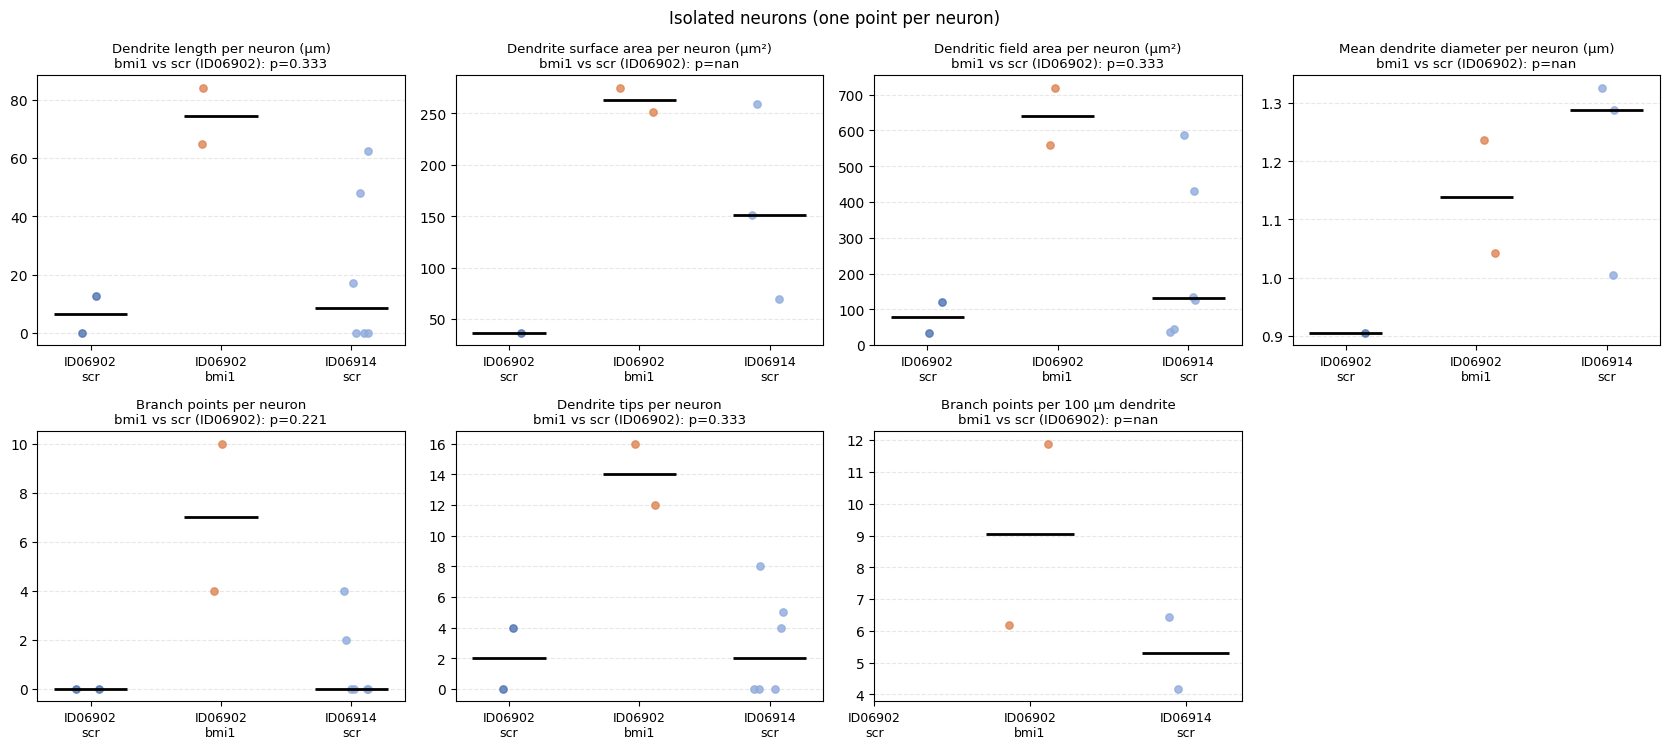

,ID06902 scr,ID06902 bmi1,ID06914 scr,n ID06902 scr,n ID06902 bmi1,n ID06914 scr,bmi1/scr (ID06902),"p bmi1 vs scr, ID06902",p bmi1 vs all scr,p scr ID06902 vs ID06914
metric,,,,,,,,,,
Dendrite length per neuron (µm),6.389,74.342,8.613,2,2,6,11.635,0.333,0.043,0.722
Dendrite surface area per neuron (µm²),36.318,263.087,151.141,1,2,3,7.244,NaN,0.267,NaN
Dendritic field area per neuron (µm²),77.452,639.159,130.523,2,2,6,8.252,0.333,0.089,0.286
Mean dendrite diameter per neuron (µm),0.905,1.139,1.288,1,2,3,1.259,NaN,1.000,NaN
Branch points per neuron,0.000,7.000,0.000,2,2,6,inf,0.221,0.039,0.513
Dendrite tips per neuron,2.000,14.000,2.000,2,2,6,7.000,0.333,0.043,0.858
Branch points per 100 µm dendrite,NaN,9.042,5.298,0,2,2,NaN,NaN,0.667,NaN


In [13]:
iso_neurons = somata[~somata['in_dense_cluster']].copy()
display(mu.add_group(iso_neurons).groupby('group').agg(n_neurons=('soma_id', 'size'),
        touching_edge=('touches_border', 'sum')).reindex(mu.GROUP_ORDER))
mu.plot_strips(iso_neurons, mu.NEURON_METRICS, ncols=4, save=os.path.join(FIG_DIR, 'isolated_neuron_metrics_airyscan.png'),
               title='Isolated neurons (one point per neuron)')
neuron_stats = mu.stats_table(iso_neurons, mu.NEURON_METRICS)
neuron_stats.to_csv(os.path.join(CSV_DIR, 'stats_isolated_neurons_airyscan.csv'))
neuron_stats.round(3)

### Same, only neurons whose dendrites stay inside the image

In [14]:
inside = iso_neurons[~iso_neurons['touches_border'].astype(bool)]
neuron_stats_in = mu.stats_table(inside, mu.NEURON_METRICS)
neuron_stats_in.to_csv(os.path.join(CSV_DIR, 'stats_isolated_neurons_inside_airyscan.csv'))
neuron_stats_in.round(3)

,ID06902 scr,ID06902 bmi1,ID06914 scr,n ID06902 scr,n ID06902 bmi1,n ID06914 scr,bmi1/scr (ID06902),"p bmi1 vs scr, ID06902",p bmi1 vs all scr,p scr ID06902 vs ID06914
metric,,,,,,,,,,
Dendrite length per neuron (µm),0.000,74.342,0.000,1,2,5,inf,NaN,0.051,NaN
Dendrite surface area per neuron (µm²),NaN,263.087,164.627,0,2,2,NaN,NaN,0.667,NaN
Dendritic field area per neuron (µm²),33.943,639.159,126.558,1,2,5,18.83,NaN,0.143,NaN
Mean dendrite diameter per neuron (µm),NaN,1.139,1.307,0,2,2,NaN,NaN,0.333,NaN
Branch points per neuron,0.000,7.000,0.000,1,2,5,inf,NaN,0.054,NaN
Dendrite tips per neuron,0.000,14.000,0.000,1,2,5,inf,NaN,0.051,NaN
Branch points per 100 µm dendrite,NaN,9.042,6.424,0,2,1,NaN,NaN,NaN,NaN


### Every isolated neuron and the dendrites assigned to it (visual check of the isolation rule)

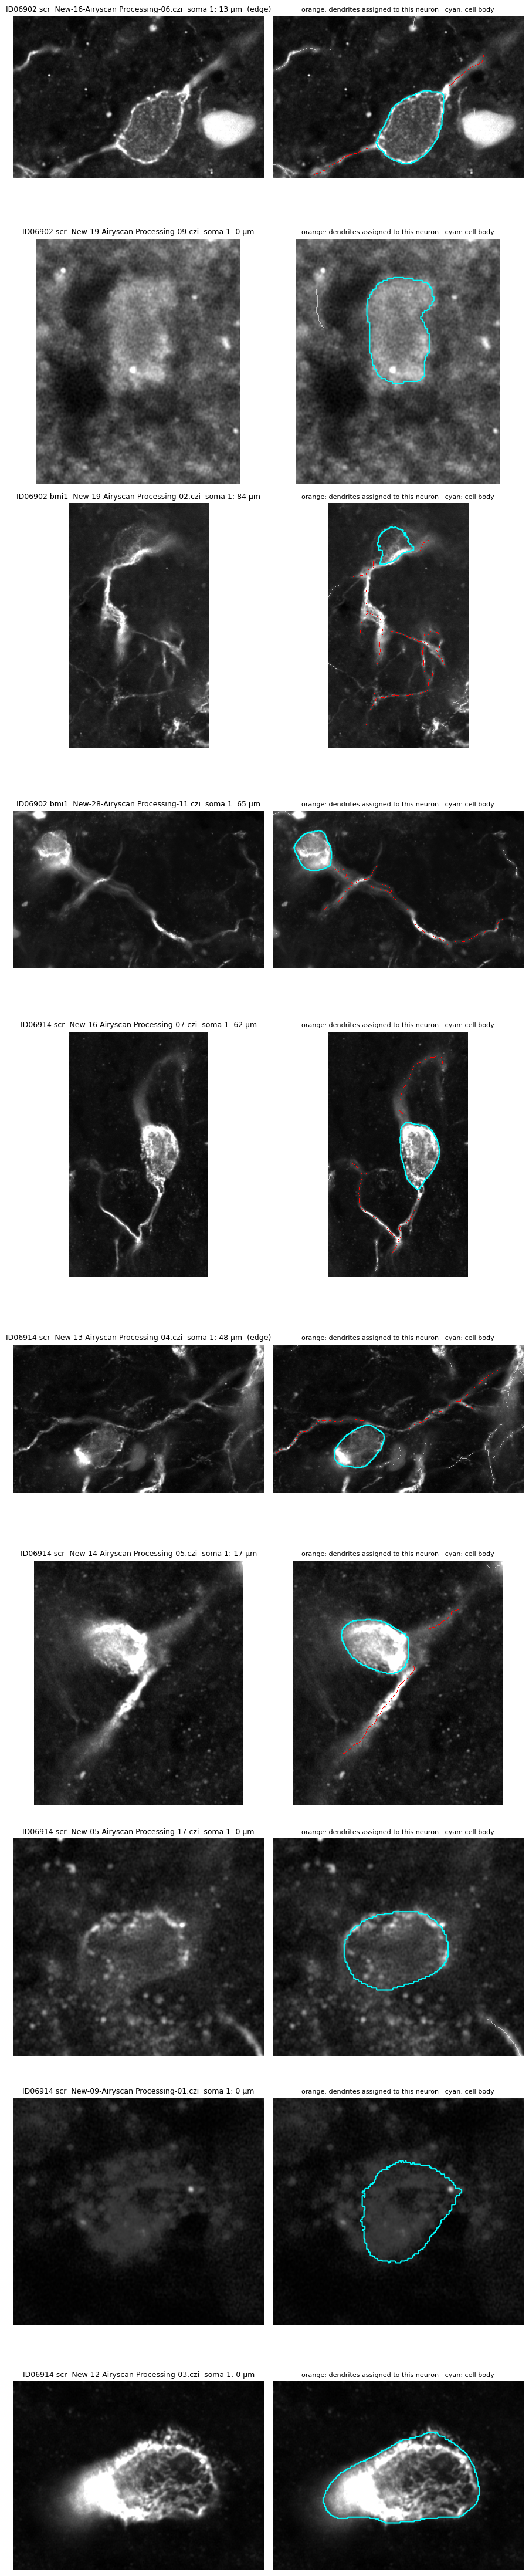

In [15]:
items = []
for gname in mu.GROUP_ORDER:
    g = mu.add_group(iso_neurons).query('group == @gname').sort_values('dend_length_um', ascending=False)
    for _, n in g.iterrows():
        p = files[(files['filename'] == n['filename']) & (files['mouse'] == n['mouse'])
                  & (files['condition'] == n['condition'])]['path'].iloc[0]
        a = mu.analyze_image(p)[3]
        items.append((f"{gname}  {n['filename']}  soma {n['soma_id']}: {n['dend_length_um']:.0f} µm"
                      + ('  (edge)' if n['touches_border'] else ''), a, n['soma_id']))
mu.plot_neuron_gallery(items, save=os.path.join(FIG_DIR, 'isolated_neuron_gallery_airyscan.png'))

## Cell bodies: one point per detected soma

,n somata
group,
ID06902 scr,6
ID06902 bmi1,20
ID06914 scr,21


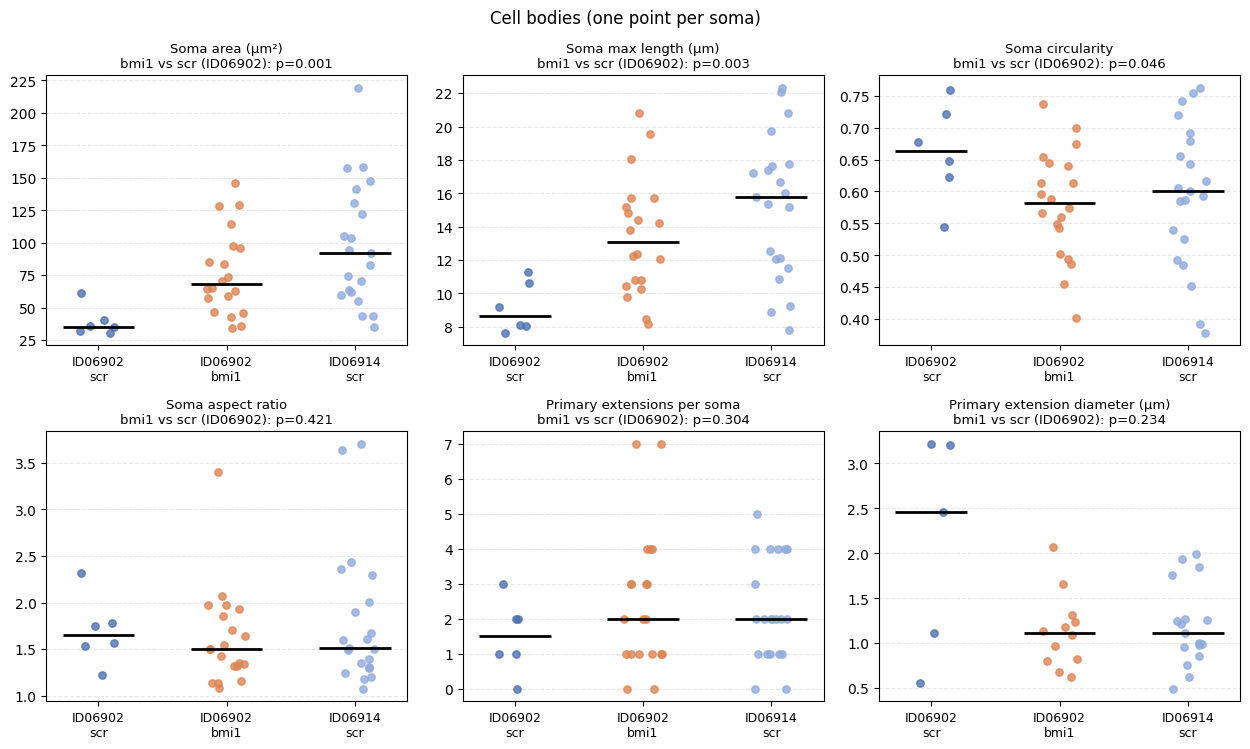

,ID06902 scr,ID06902 bmi1,ID06914 scr,n ID06902 scr,n ID06902 bmi1,n ID06914 scr,bmi1/scr (ID06902),"p bmi1 vs scr, ID06902",p bmi1 vs all scr,p scr ID06902 vs ID06914
metric,,,,,,,,,,
Soma area (µm²),35.135,67.924,91.647,6,20,21,1.933,0.001,0.923,0.000
Soma max length (µm),8.641,13.085,15.760,6,20,21,1.514,0.003,0.755,0.001
Soma circularity,0.663,0.581,0.601,6,20,21,0.877,0.046,0.241,0.175
Soma aspect ratio,1.654,1.503,1.509,6,20,21,0.909,0.421,0.445,0.712
Primary extensions per soma,1.500,2.000,2.000,6,20,21,1.333,0.304,0.668,0.306
Primary extension diameter (µm),2.455,1.111,1.108,5,12,17,0.453,0.234,0.482,0.164


,in dense cluster,all somata
group,,
ID06902 scr,4,6
ID06902 bmi1,18,20
ID06914 scr,15,21


In [16]:
if len(somata):
    display(mu.add_group(somata)['group'].value_counts().reindex(mu.GROUP_ORDER).rename('n somata').to_frame())
    mu.plot_strips(somata, mu.SOMA_METRICS, ncols=3, save=os.path.join(FIG_DIR, 'soma_metrics_airyscan.png'),
                   title='Cell bodies (one point per soma)')
    soma_stats = mu.stats_table(somata, mu.SOMA_METRICS)
    soma_stats.to_csv(os.path.join(CSV_DIR, 'stats_somata_airyscan.csv'))
    display(soma_stats.round(3))
    display(mu.add_group(somata).groupby('group')['in_dense_cluster'].agg(['sum', 'size'])
            .rename(columns={'sum': 'in dense cluster', 'size': 'all somata'}).reindex(mu.GROUP_ORDER))

## Findings (Airyscan, 58 images, single planes)

The Airyscan images agree with the regular CZI images.

**1. bmi1 neurons sit in dense clusters.** 29% of bmi1 extension length lies in dense graft cores,
against 0% in both scr mice (p = 0.003 vs same-mouse scr, p = 0.002 vs all scr).

**2. Isolated bmi1 extensions branch more, as a trend.** 9.6 branch points per 100 µm against 7.0 (scr
ID06902) and 7.9 (scr ID06914); p = 0.068 and 0.080. Same direction as the CZI data, with fewer images.

**3. Extension diameter: not attributable to bmi1.** Isolated extensions: bmi1 0.93 µm, scr ID06902
0.76 µm (p = 0.022), but scr ID06914 1.05 µm, thicker than bmi1 (bmi1 vs all scr p = 0.45).

**4. Soma shape: no reliable difference.** bmi1 somata are larger than scr ID06902 (68 vs 35 µm²,
p = 0.001; only 6 scr somata), but scr ID06914 somata are larger (92 µm²). bmi1 vs all scr p = 0.92.

**5. Swellings (paper Fig 3F): no difference.** Isolated extensions: 0% of bmi1 branches swollen
(median per image) against 2.0% and 0% for the two scr mice (p = 0.40). Per length: 0 vs 0.75 and
0.20 per 100 µm (p = 0.66). Too few swellings were found for a strong statement; the visual check
shows some detections at bends or branch points.

**Limits.**
- bmi1 comes from one mouse (ID06902). A bmi1 vs scr difference cannot be fully separated from a difference between mice; the two scr mice already differ in diameter and soma size.
- Images are fields picked by the experimenter, not random samples. Statistics are per image (or per soma), not per animal.
- Cell bodies are found by Cellpose-SAM with filters. It misses some and splits a few large somata, so treat the soma numbers as rough.